**Instructions:**
- প্রতিটি cell এ `# YOUR CODE HERE` এর জায়গায় তোমার code লেখো।
- Expected output এর সাথে নিজের output মেলাও।
- `Shift + Enter` দিয়ে cell run করো।

---

## ⚙️ Setup — Run This First

In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

np.random.seed(42)
data = {
    'Age':        [25, 32, np.nan, 45, 28, 60, 22, 38, np.nan, 55, 29, 200, 34, 41, 26],
    'Salary':     [30000, 55000, 48000, np.nan, 32000, 75000, 28000, 60000, 41000, 70000, 33000, 52000, np.nan, 63000, 29000],
    'City':       ['Dhaka','Chittagong','Dhaka','Sylhet',np.nan,'Dhaka','Rajshahi','Chittagong','Dhaka','Sylhet','Rajshahi','Dhaka','Chittagong',np.nan,'Dhaka'],
    'Education':  ['HSC','Graduate','Graduate','Masters','HSC','PhD','HSC','Graduate','Masters','PhD','HSC','Graduate','Graduate','Masters','HSC'],
    'Experience': [2, 8, 5, 15, 3, 30, 1, 12, 7, 25, 2, 9, 6, 18, 3],
    'Purchased':  [0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0]
}
df = pd.DataFrame(data)
print('Dataset loaded! Shape:', df.shape)
df.head()

Dataset loaded! Shape: (15, 6)


,Age,Salary,City,Education,Experience,Purchased
0,25.0,30000.0,Dhaka,HSC,2,0
1,32.0,55000.0,Chittagong,Graduate,8,1
2,NaN,48000.0,Dhaka,Graduate,5,1
3,45.0,NaN,Sylhet,Masters,15,1
4,28.0,32000.0,NaN,HSC,3,0


---
# 📌 Section 1: Exploratory Data Analysis
**Module 01 & 02**

### 🟢 EASY &nbsp;&nbsp; Question 1
Dataset এর **shape** বের করো — কতটি row এবং column আছে?

In [141]:
# YOUR CODE HERE
# Hint: df.shape

df.shape
# There are 15 rows and 6 columns

(15, 6)

**Expected Output:** `(15, 6)`

### 🟢 EASY &nbsp;&nbsp; Question 2
প্রতিটি column এর **data type** দেখাও।

In [142]:
# YOUR CODE HERE
# Hint: df.dtypes

df.dtypes


,0
Age,float64
Salary,float64
City,object
Education,object
Experience,int64
Purchased,int64


### 🟢 EASY &nbsp;&nbsp; Question 3
Dataset এর **statistical summary** দেখাও — mean, std, min, max।

In [143]:
# YOUR CODE HERE
# Hint: df.describe()
df.describe()

,Age,Salary,Experience,Purchased
count,13.000000,13.000000,15.000000,15.000000
mean,48.846154,47384.615385,9.733333,0.600000
std,46.857668,16474.922668,8.778762,0.507093
min,22.000000,28000.000000,1.000000,0.000000
25%,28.000000,32000.000000,3.000000,0.000000
50%,34.000000,48000.000000,7.000000,1.000000
75%,45.000000,60000.000000,13.500000,1.000000
max,200.000000,75000.000000,30.000000,1.000000


### 🟢 EASY &nbsp;&nbsp; Question 4
**City** column এ কতটি unique value আছে এবং প্রতিটি কতবার আসে?

In [144]:
# YOUR CODE HERE
# Hint: .nunique() এবং .value_counts()
df['City'].nunique()
df['City'].value_counts()

,count
City,
Dhaka,6
Chittagong,3
Sylhet,2
Rajshahi,2


### 🟡 MEDIUM &nbsp;&nbsp; Question 5
**Age** column এর mean, median এবং mode আলাদাভাবে বের করো এবং তিনটি একসাথে print করো।

In [145]:
# YOUR CODE HERE
# Hint: .mean(), .median(), .mode()[0]
print(f'Mean of Age : {df['Age'].mean()}')
print(f'Median of Age : {df['Age'].median()}')
print(f'Mode of Age : {df['Age'].mode()[0]}')

Mean of Age : 48.84615384615385
Median of Age : 34.0
Mode of Age : 22.0


### 🟡 MEDIUM &nbsp;&nbsp; Question 6
**Age** এর distribution দেখানোর জন্য histogram plot করো। Title এবং axis labels দাও।

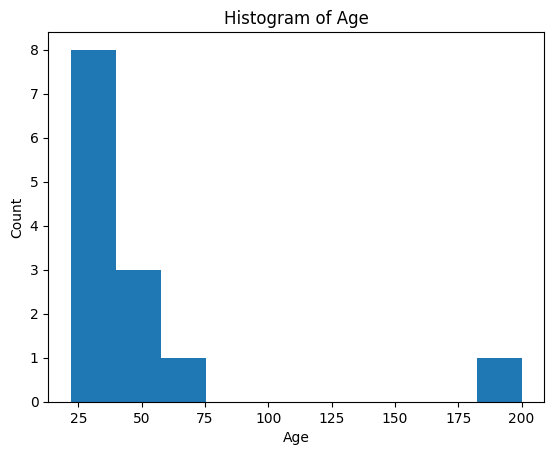

In [146]:
# YOUR CODE HERE
# Hint: plt.hist() বা df['Age'].plot(kind='hist')
# plt.title(), plt.xlabel(), plt.ylabel() দিতে ভুলো না

plt.hist(x = df['Age'])

plt.title('Histogram of Age')
plt.xlabel('Age')
plt.ylabel('Count')

plt.show()

### 🟡 MEDIUM &nbsp;&nbsp; Question 7
**Salary vs Experience** scatter plot করো এবং দেখো কোনো pattern আছে কিনা।

<Axes: xlabel='Experience', ylabel='Salary'>

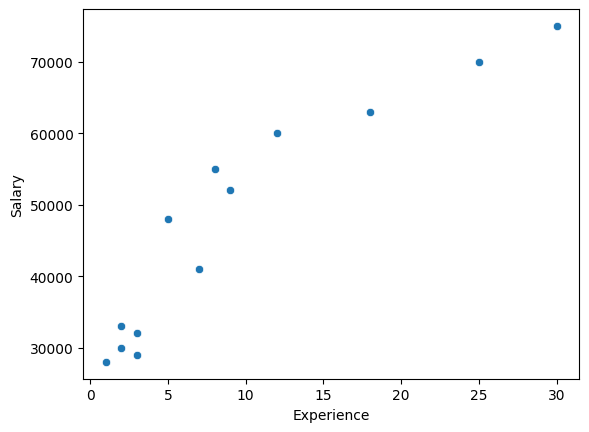

In [147]:
# YOUR CODE HERE
# Hint: sns.scatterplot(data=df, x='Experience', y='Salary')

sns.scatterplot(data = df, x = 'Experience', y = 'Salary')


### 🔴 HARD &nbsp;&nbsp; Question 8
Numerical columns এর correlation বের করো এবং **heatmap** দিয়ে visualize করো। `annot=True` দাও।

> চিন্তা করো: Age এবং Experience এর মধ্যে কি strong correlation আছে? কেন?

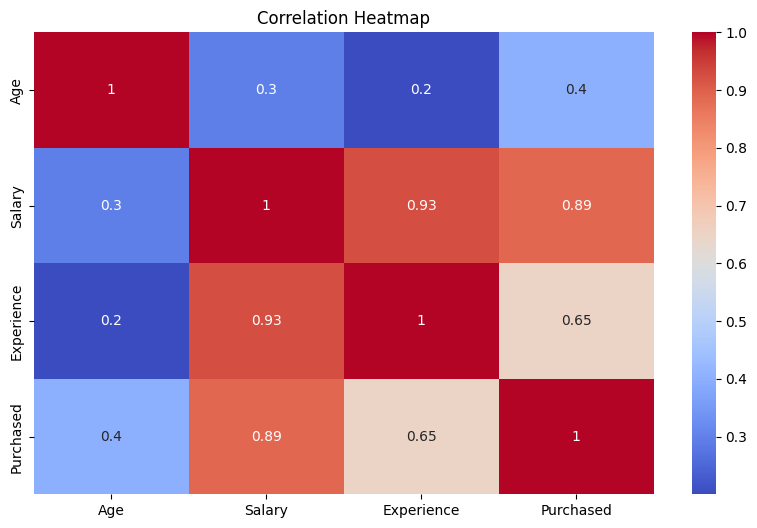

In [148]:
# YOUR CODE HERE
# Hint: df.corr() → sns.heatmap(..., annot=True, cmap='coolwarm')

# correlation matrix
corr = df.corr(numeric_only=True)

# heatmap
plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

Age and Experience usually show strong positive correlation because as age increases, work experience tends to increase as well.

---
# 📌 Section 2: Train-Test Split & Missing Value Handling
**Module 03**

### 🟢 EASY &nbsp;&nbsp; Question 9
প্রতিটি column এ **কতটি missing value** আছে তা বের করো।

In [149]:
# YOUR CODE HERE
# Hint: .isnull().sum()

df.isnull().sum()


,0
Age,2
Salary,2
City,2
Education,0
Experience,0
Purchased,0


**Expected:** Age=2, Salary=2, City=2

### 🟢 EASY &nbsp;&nbsp; Question 10
**Age** এর missing values **mean** দিয়ে এবং **City** এর missing values **mode** দিয়ে fill করো।

In [150]:
df_clean = df.copy()

# YOUR CODE HERE
# Age → mean
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].mean())
# City → mode
df_clean['City'] = df_clean['City'].fillna(df_clean['City'].mode())


### 🟡 MEDIUM &nbsp;&nbsp; Question 11
**Salary** এর missing values **median** দিয়ে fill করো। Fill করার আগে ও পরে missing count দেখাও।

In [151]:
# YOUR CODE HERE
# Before count print করো

print(f'Missing values : {df_clean['Salary'].isnull().sum()}')

# Fill করো

df_clean['Salary'] = df_clean['Salary'].fillna(df_clean['Salary'].median())

# After count print করো
print(f'Missing values : {df_clean['Salary'].isnull().sum()}')


Missing values : 2
Missing values : 0


### 🟡 MEDIUM &nbsp;&nbsp; Question 12
**Train-Test Split** করো — 80% training, 20% testing। `random_state=42`।

> Feature (X): Age, Salary, Experience | Target (y): Purchased

In [152]:
X = df_clean[['Age', 'Salary', 'Experience']]
y = df_clean['Purchased']

# YOUR CODE HERE
# X_train, X_test, y_train, y_test = train_test_split(...)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Print sizes

print(f'Size of X_train : {X_train.shape}')
print(f'Size of X_test : {X_test.shape}')

print(f'Size of y_train : {y_train.shape}')
print(f'Size of y_test : {y_test.shape}')

Size of X_train : (12, 3)
Size of X_test : (3, 3)
Size of y_train : (12,)
Size of y_test : (3,)


**Expected:** Train size: 12, Test size: 3

### 🔴 HARD &nbsp;&nbsp; Question 13
Train-Test Split করার পরে `y_train` এবং `y_test` এ **class distribution** (0 এবং 1 এর ratio) দেখাও। Distribution কি balanced?

> Hint: `.value_counts(normalize=True)` দিয়ে percentage বের করো।

In [153]:
# YOUR CODE HERE
# y_train distribution

train_dist = y_train.value_counts(normalize = True) * 100

print(train_dist)

# y_test distribution

test_dist = y_test.value_counts(normalize = True) * 100

print(test_dist)

# Observation:
# Train set এ class 0 ≈ 52%, class 1 ≈ 48%
# Test set এ class 0 ≈ 50%, class 1 ≈ 50%
# তাই distribution প্রায় balanced আছে।


Purchased
1    58.333333
0    41.666667
Name: proportion, dtype: float64
Purchased
1    66.666667
0    33.333333
Name: proportion, dtype: float64


---
# 📌 Section 3: Outlier Detection and Handling
**Module 05 & 06**

### 🟢 EASY &nbsp;&nbsp; Question 14
**Age** column এর **boxplot** তৈরি করো।

<Axes: xlabel='Age'>

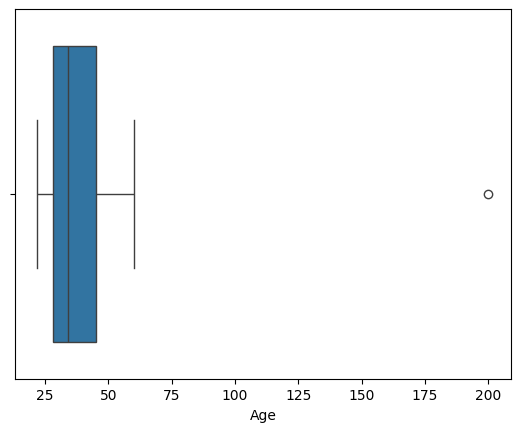

In [154]:
# YOUR CODE HERE
# Hint: sns.boxplot(y=df_clean['Age'])

sns.boxplot(data = df, x = df['Age'])


**Note:** Age=200 clearly একটি outlier।

### 🟡 MEDIUM &nbsp;&nbsp; Question 15
**IQR Method** দিয়ে **Age** column এর outlier detect করো এবং outlier rows দেখাও।

> IQR = Q3 - Q1 | Lower = Q1 - 1.5×IQR | Upper = Q3 + 1.5×IQR

In [155]:
Q1 = df_clean['Age'].quantile(0.25)
Q3 = df_clean['Age'].quantile(0.75)

# YOUR CODE HERE
# IQR calculate করো

IQR = Q3 - Q1

# Lower এবং Upper bound

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Outlier rows দেখাও

outliers = df_clean[ ( df_clean['Age'] < lower ) | ( df_clean['Age'] > upper ) ]

display(outliers)

,Age,Salary,City,Education,Experience,Purchased
11,200.0,52000.0,Dhaka,Graduate,9,1


**Expected:** Age=200 row outlier হিসেবে detected হবে।

### 🟡 MEDIUM &nbsp;&nbsp; Question 16
**Z-Score Method** দিয়ে outlier detect করো। |Z| > 3 হলে outlier।

> Z = (x - mean) / std

In [156]:
# YOUR CODE HERE
mean_age = df_clean['Age'].mean()
std_age  = df_clean['Age'].std()

# Z-score calculate করো

z = ( df_clean['Age'] - mean_age ) / std_age

# |Z| > 3 এমন rows দেখাও
df_clean = df_clean[abs(df_clean['Age']) > 3]

display(df_clean)


,Age,Salary,City,Education,Experience,Purchased
0,25.000000,30000.0,Dhaka,HSC,2,0
1,32.000000,55000.0,Chittagong,Graduate,8,1
2,48.846154,48000.0,Dhaka,Graduate,5,1
3,45.000000,48000.0,Sylhet,Masters,15,1
4,28.000000,32000.0,NaN,HSC,3,0
5,60.000000,75000.0,Dhaka,PhD,30,1
6,22.000000,28000.0,Rajshahi,HSC,1,0
7,38.000000,60000.0,Chittagong,Graduate,12,1
8,48.846154,41000.0,Dhaka,Masters,7,0
9,55.000000,70000.0,Sylhet,PhD,25,1


### 🟡 MEDIUM &nbsp;&nbsp; Question 17
IQR method এ detected outlier rows **remove** করো। নতুন shape দেখাও।

In [157]:
Q1 = df_clean['Age'].quantile(0.25)
Q3 = df_clean['Age'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Remove outliers
df_clean = df_clean[( df_clean['Age'] >= lower ) & ( df_clean['Age'] <= upper )]

# New shape
print("New shape:", df_clean.shape)

New shape: (14, 6)


**Expected:** Shape (14, 6) — 1 row removed.

### 🔴 HARD &nbsp;&nbsp; Question 18
Outlier remove করার বদলে **cap** করো (Winsorization)। তারপর before vs after boxplot side-by-side দেখাও।

> Cap মানে: outlier value কে bound এর value দিয়ে replace করা।

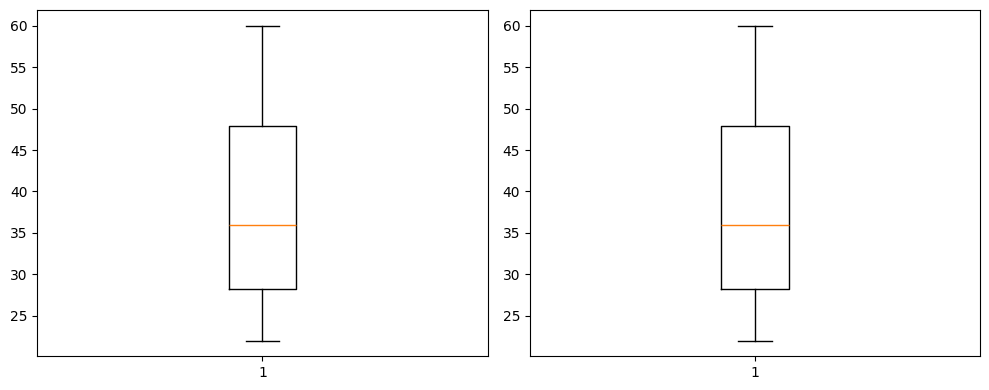

In [158]:
df_capped = df_clean.copy()

# YOUR CODE HERE
# Step 1: Cap করো
# Hint: df_capped['Age'] = df_capped['Age'].clip(lower=lower_bound, upper=upper_bound)

Q1 = df_capped['Age'].quantile(0.25)
Q3 = df_capped['Age'].quantile(0.75)

IQR = Q3 - Q1

lower = max(0, Q1 - 1.5 * IQR)

upper = Q3 + 1.5 * IQR

df_capped['Age'] = df_capped['Age'].clip( lower, upper )

# Step 2: Before vs After boxplot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].boxplot(df_clean['Age'])
axes[1].boxplot(df_capped['Age'])

# axes[0] → Before (df_clean)
# axes[1] → After (df_capped)
plt.tight_layout()
plt.show()

---
# 📌 Section 4: Encoding
**Module 07**

### 🟢 EASY &nbsp;&nbsp; Question 19
**Label Encoding** দিয়ে **Education** column কে numerical করো।

In [159]:
df_encoded = df_clean.copy()
le = LabelEncoder()

# YOUR CODE HERE
# df_encoded['Education_Encoded'] = le.fit_transform(...)

df_encoded['Education_Encoded'] = le.fit_transform(df_encoded['Education'])

df_encoded

,Age,Salary,City,Education,Experience,Purchased,Education_Encoded
0,25.000000,30000.0,Dhaka,HSC,2,0,1
1,32.000000,55000.0,Chittagong,Graduate,8,1,0
2,48.846154,48000.0,Dhaka,Graduate,5,1,0
3,45.000000,48000.0,Sylhet,Masters,15,1,2
4,28.000000,32000.0,NaN,HSC,3,0,1
5,60.000000,75000.0,Dhaka,PhD,30,1,3
6,22.000000,28000.0,Rajshahi,HSC,1,0,1
7,38.000000,60000.0,Chittagong,Graduate,12,1,0
8,48.846154,41000.0,Dhaka,Masters,7,0,2
9,55.000000,70000.0,Sylhet,PhD,25,1,3


### 🟢 EASY &nbsp;&nbsp; Question 20
**One-Hot Encoding** দিয়ে **City** column কে encode করো। `pd.get_dummies()` ব্যবহার করো।

In [160]:
# YOUR CODE HERE
# Hint: pd.get_dummies(df_encoded, columns=['City'], drop_first=True)

df_encoded = pd.get_dummies(df_encoded, columns = ['City'], drop_first = True)

df_encoded

,Age,Salary,Education,Experience,Purchased,Education_Encoded,City_Dhaka,City_Rajshahi,City_Sylhet
0,25.000000,30000.0,HSC,2,0,1,True,False,False
1,32.000000,55000.0,Graduate,8,1,0,False,False,False
2,48.846154,48000.0,Graduate,5,1,0,True,False,False
3,45.000000,48000.0,Masters,15,1,2,False,False,True
4,28.000000,32000.0,HSC,3,0,1,False,False,False
5,60.000000,75000.0,PhD,30,1,3,True,False,False
6,22.000000,28000.0,HSC,1,0,1,False,True,False
7,38.000000,60000.0,Graduate,12,1,0,False,False,False
8,48.846154,41000.0,Masters,7,0,2,True,False,False
9,55.000000,70000.0,PhD,25,1,3,False,False,True


**Note:** `drop_first=True` দিলে dummy variable trap avoid হয়।

### 🟡 MEDIUM &nbsp;&nbsp; Question 21
Label Encoded **Education** এর mapping dictionary দেখাও — কোন label কোন number পেয়েছে।

In [161]:
# YOUR CODE HERE
# Hint: dict(zip(le.classes_, le.transform(le.classes_)))

dict(zip(le.classes_, le.transform(le.classes_)))


{'Graduate': np.int64(0),
 'HSC': np.int64(1),
 'Masters': np.int64(2),
 'PhD': np.int64(3)}

**Expected:** `{'Graduate': 0, 'HSC': 1, 'Masters': 2, 'PhD': 3}`

### 🔴 HARD &nbsp;&nbsp; Question 22
Label Encoding এবং One-Hot Encoding এর মধ্যে পার্থক্য কী? **Education** column এ কোনটা ব্যবহার করা সঠিক এবং কেন?

> দুটো method ই apply করো এবং output compare করো। তারপর নিচে comment এ তোমার reasoning লেখো।

In [162]:
# Method 1: Label Encoding
from sklearn.preprocessing import OneHotEncoder

df_label = df_clean.copy()

le = LabelEncoder()
df_label['Education'] = le.fit_transform(df_label['Education'])

df_label

# Method 2: One-Hot Encoding

df_onehot = df_clean.copy()

ohe =  OneHotEncoder(sparse_output = False).set_output(transform = 'pandas')

encoded_Edu = ohe.fit_transform(df_onehot[['Education']])

df_onehot = pd.concat([df_onehot, encoded_Edu], axis = 1)

df_onehot

# তোমার answer (comment এ লেখো):
# Education column এ One Hot Encoder ভালো কারণ Education একটি nominal categorical variable


,Age,Salary,City,Education,Experience,Purchased,Education_Graduate,Education_HSC,Education_Masters,Education_PhD
0,25.000000,30000.0,Dhaka,HSC,2,0,0.0,1.0,0.0,0.0
1,32.000000,55000.0,Chittagong,Graduate,8,1,1.0,0.0,0.0,0.0
2,48.846154,48000.0,Dhaka,Graduate,5,1,1.0,0.0,0.0,0.0
3,45.000000,48000.0,Sylhet,Masters,15,1,0.0,0.0,1.0,0.0
4,28.000000,32000.0,NaN,HSC,3,0,0.0,1.0,0.0,0.0
5,60.000000,75000.0,Dhaka,PhD,30,1,0.0,0.0,0.0,1.0
6,22.000000,28000.0,Rajshahi,HSC,1,0,0.0,1.0,0.0,0.0
7,38.000000,60000.0,Chittagong,Graduate,12,1,1.0,0.0,0.0,0.0
8,48.846154,41000.0,Dhaka,Masters,7,0,0.0,0.0,1.0,0.0
9,55.000000,70000.0,Sylhet,PhD,25,1,0.0,0.0,0.0,1.0


---
# 📌 Section 5: Scaling
**Module 08**

### 🟢 EASY &nbsp;&nbsp; Question 23
**MinMaxScaler** দিয়ে **Experience** column কে 0–1 এর মধ্যে scale করো।

> Formula: x_scaled = (x - min) / (max - min)

In [163]:
mm_scaler = MinMaxScaler()
df_scaled  = df_clean.copy()

# YOUR CODE HERE

df_scaled['Experience'] = ( df_scaled['Experience'] - df_scaled['Experience'].min() ) / ( df_scaled['Experience'].max() - df_scaled['Experience'].min() )

df_scaled['Experience']


,Experience
0,0.034483
1,0.241379
2,0.137931
3,0.482759
4,0.068966
5,1.000000
6,0.000000
7,0.379310
8,0.206897
9,0.827586


**Expected:** Experience values এখন 0.0 থেকে 1.0 এর মধ্যে।

### 🟡 MEDIUM &nbsp;&nbsp; Question 24
**StandardScaler** দিয়ে **Age** এবং **Salary** scale করো। Scaling এর পর mean ≈ 0 এবং std ≈ 1 verify করো।

In [164]:
from math import remainder
from sklearn.compose import ColumnTransformer
std_scaler = StandardScaler()

# YOUR CODE HERE
# Scale করো

encoder_scaler = ColumnTransformer(
    transformers = [
        ( 'encode', StandardScaler(), ['Age', 'Salary'] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

encoder_scaler.set_output(transform = 'pandas')

df_scaled = encoder_scaler.fit_transform(df_scaled)

# Verify: mean এবং std print করো

round(df_scaled[['Age', 'Salary']].mean(),2)
round(df_scaled[['Age', 'Salary']].std(), 2)

,0
Age,1.04
Salary,1.04


**Expected:** Mean ≈ 0.0, Std ≈ 1.0

### 🟡 MEDIUM &nbsp;&nbsp; Question 25
**Age** column এর scaling এর আগে ও পরে distribution **side-by-side histogram** দিয়ে compare করো।

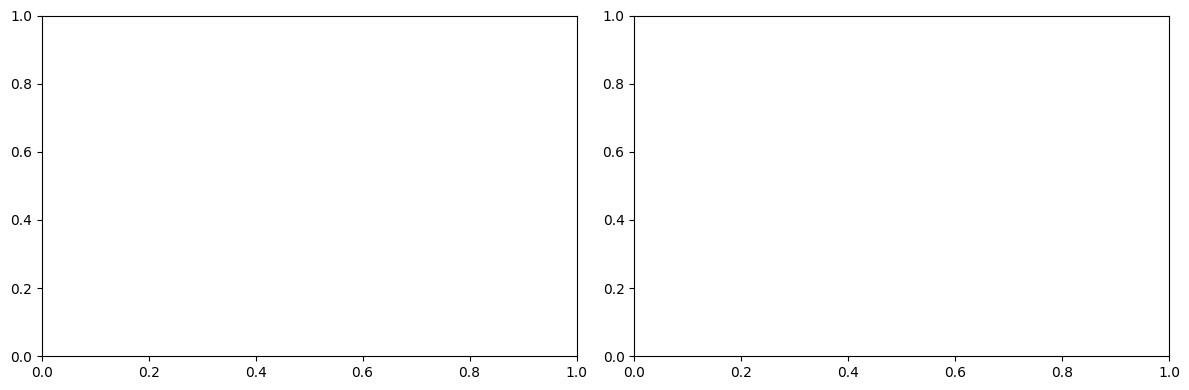

In [165]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# YOUR CODE HERE
# axes[0] → Before scaling
# axes[1] → After scaling

plt.tight_layout()
plt.show()

### 🔴 HARD &nbsp;&nbsp; Question 26
StandardScaler এবং MinMaxScaler এর মধ্যে পার্থক্য কী? **Salary** column এ দুটোই apply করো এবং output compare করো।

> কোন situation এ কোনটা use করবে? Comment এ reasoning লেখো।

In [166]:
salary = df_clean[['Salary']]

# StandardScaler apply করো

ss = StandardScaler()

salary_Standard = ss.fit_transform(salary)

# print(f'StandardScaler Output : \n {salary_Standard}')

# MinMaxScaler apply করো

mms = MinMaxScaler()

salary_mms = mms.fit_transform(salary)

# print(f'MinMaxScaler Output : \n {salary_mms}')

# দুটো result compare করো (print অথবা plot)

comparison = pd.DataFrame({
    'Original': salary['Salary'],
    'StandardScaler': salary_Standard.ravel(),
    'MinMaxScaler': salary_mms.ravel()
})

print(comparison.head())

   Original  StandardScaler  MinMaxScaler
0   30000.0       -1.127618      0.042553
1   55000.0        0.516825      0.574468
2   48000.0        0.056381      0.425532
3   48000.0        0.056381      0.425532
4   32000.0       -0.996063      0.085106


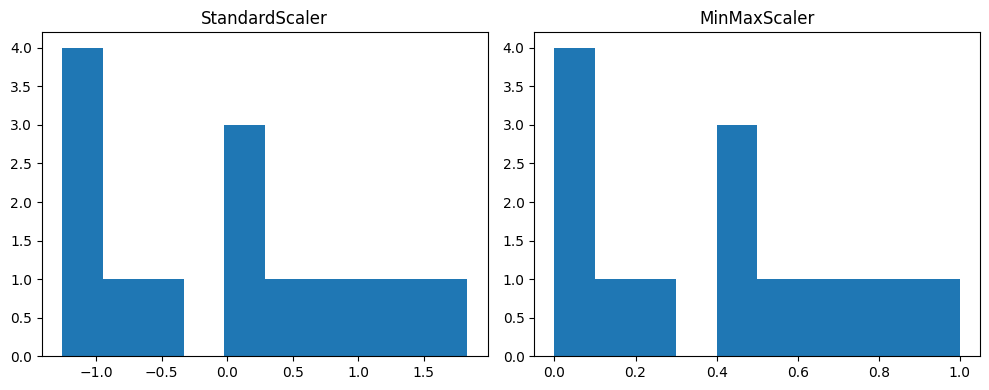

In [167]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(salary_Standard, bins=10)
axes[0].set_title("StandardScaler")

axes[1].hist(salary_mms, bins=10)
axes[1].set_title("MinMaxScaler")

plt.tight_layout()
plt.show()

---
# 🌟 Bonus: Full Pipeline
**Combine everything — end-to-end preprocessing**

### 🔴 HARD &nbsp;&nbsp; Question 27 (Bonus)
নিচের সব steps follow করে একটি **complete preprocessing pipeline** তৈরি করো:

1. Missing values handle করো
2. Outliers cap করো (IQR method)
3. City → One-Hot Encode
4. Education → Label Encode
5. Age, Salary, Experience → StandardScale
6. 80/20 Train-Test Split
7. Final train/test shape print করো

In [168]:
from sklearn.impute import SimpleImputer

df_pipeline = df.copy()

# Step 1: Missing values

print(f'{df_pipeline.isnull().sum()}')

# print(f'{df_pipeline['Age'].describe()})')

# print(f'{df_pipeline['Salary'].describe()}')

# df_pipeline['Age'].skew()
# df_pipeline['Salary'].skew()

# fig, axes = plt.subplots(1, 2, figsize=(10,4))

# sns.kdeplot(data = df_pipeline, x = 'Age', ax = axes[0])
# axes[0].set_title("Age Distribution")

# sns.kdeplot(data = df_pipeline, x = 'Salary', ax = axes[1])
# axes[1].set_title("Salary Distribution")

# sns.boxplot(data = df_pipeline, x = 'Age', ax = axes[0])

# sns.boxplot(data = df_pipeline, x = 'Salary', ax = axes[1])

# plt.show()

df_pipeline['Age'] = df_pipeline['Age'].fillna(df_pipeline['Age'].median())

df_pipeline['Salary'] = df_pipeline['Salary'].fillna(df_pipeline['Salary'].mean())

# df_pipeline.isnull().sum()

# df_pipeline['City'].unique()

city_imputer = SimpleImputer(missing_values=np.nan , strategy='most_frequent')

df_pipeline['City'] = city_imputer.fit_transform(df_pipeline[['City']]).ravel()

df_pipeline.isnull().sum()


# Step 2: Outlier capping

Q1 = df_pipeline['Age'].quantile(0.25)
Q3 = df_pipeline['Age'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# print(f'Maximum Age : {df_pipeline['Age'].max()}')

df_pipeline['Age'] = df_pipeline['Age'].clip(lower, upper)

# df_pipeline['Age'].max()


Q1 = df_pipeline['Salary'].quantile(0.25)
Q3 = df_pipeline['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f'Maximum Salary : {df_pipeline['Salary'].max()}')

df_pipeline['Salary'] = df_pipeline['Salary'].clip(lower, upper)

df_pipeline['Salary'].max()

Q1 = df_pipeline['Salary'].quantile(0.25)
Q3 = df_pipeline['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# print(f'Maximum Salary : {df_pipeline['Salary'].max()}')

df_pipeline['Salary'] = df_pipeline['Salary'].clip(lower, upper)

df_pipeline['Salary'].max()



Q1 = df_pipeline['Experience'].quantile(0.25)
Q3 = df_pipeline['Experience'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# print(f'Maximum Experience : {df_pipeline['Experience'].max()}')

df_pipeline['Experience'] = df_pipeline['Experience'].clip(lower, upper)

df_pipeline['Experience'].max()

# Step 3: One-Hot Encoding

df_pipeline = pd.get_dummies(df_pipeline, columns=['City'], drop_first=True)

# df_pipeline

# Step 4: Label Encoding

le = LabelEncoder()
df_pipeline['Education'] = le.fit_transform(df_pipeline['Education'])

df_pipeline

# Step 5: Standard Scaling

print(df_pipeline.head(5))

encoder_scaler = ColumnTransformer(
    transformers = [
        ( 'all', StandardScaler(), ['Age', 'Salary', 'Experience'] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

encoder_scaler.set_output(transform = 'pandas')

df_pipeline = encoder_scaler.fit_transform(df_pipeline)

df_pipeline

# Step 6: Train-Test Split

X = df_pipeline.drop('Purchased', axis = 1)
y = df_pipeline['Purchased']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


# Step 7: Print shapes

print(f'X_train shape : {X_train.shape}')
print(f'X_test shape : {X_test.shape}')

print(f'y_train shape : {y_train.shape}')
print(f'y_test shape : {y_test.shape}')

print('Pipeline complete!')


Age           2
Salary        2
City          2
Education     0
Experience    0
Purchased     0
dtype: int64
Maximum Salary : 75000.0
    Age        Salary  Education  Experience  Purchased  City_Dhaka  \
0  25.0  30000.000000          1         2.0          0        True   
1  32.0  55000.000000          0         8.0          1       False   
2  34.0  48000.000000          0         5.0          1        True   
3  45.0  47384.615385          2        15.0          1       False   
4  28.0  32000.000000          1         3.0          0        True   

   City_Rajshahi  City_Sylhet  
0          False        False  
1          False        False  
2          False        False  
3          False         True  
4          False        False  
X_train shape : (12, 7)
X_test shape : (3, 7)
y_train shape : (12,)
y_test shape : (3,)
Pipeline complete!
